# Sentiment Analysis of Customer Reviews

**Oasis Infobyte – Data Analytics Internship**

## Project Objective

The objective of this project is to analyse customer reviews and identify the sentiments expressed in the text using Natural Language Processing (NLP).

The project will focus on preprocessing textual data, classifying customer opinions as positive, negative or neutral, and visualising sentiment patterns.

The analysis aims to provide insights into customer satisfaction and identify common opinions expressed in reviews.

## Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- NLTK
- Google Colab

In [6]:
!pip -q install nltk wordcloud

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import re

from nltk.sentiment import SentimentIntensityAnalyzer

nltk.download("vader_lexicon")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [8]:
from google.colab import files

uploaded = files.upload()

In [9]:
import glob

print("Available CSV files:")
print(glob.glob("/content/*.csv"))

Available CSV files:
['/content/Reviews.csv']


## Dataset Loading and Initial Exploration

The Amazon Fine Food Reviews dataset contains customer reviews and product ratings.

This stage examines the dataset's structure, identifies missing values and duplicate records, and explores the distribution of customer ratings.

The findings will help prepare the review text for sentiment analysis.

In [10]:
import pandas as pd

df = pd.read_csv("/content/Reviews.csv")

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst Five Records:")
display(df.head())

Dataset Shape: (568454, 10)

Column Names:
['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text']

First Five Records:


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [11]:
# Select a reproducible random sample
df_sample = df.sample(
    n=min(10000, len(df)),
    random_state=42
).copy()

print("Sample Dataset Shape:", df_sample.shape)

display(df_sample.head())

Sample Dataset Shape: (10000, 10)


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
165256,165257,B000EVG8J2,A1L01D2BD3RKVO,"B. Miller ""pet person""",0,0,5,1268179200,Crunchy & Good Gluten-Free Sandwich Cookies!,Having tried a couple of other brands of glute...
231465,231466,B0000BXJIS,A3U62RE5XZDP0G,Marty,0,0,5,1298937600,great kitty treats,My cat loves these treats. If ever I can't fin...
427827,427828,B008FHUFAU,AOXC0JQQZGGB6,Kenneth Shevlin,0,2,3,1224028800,COFFEE TASTE,A little less than I expected. It tends to ha...
433954,433955,B006BXV14E,A3PWPNZVMNX3PA,rareoopdvds,0,1,2,1335312000,So the Mini-Wheats were too big?,"First there was Frosted Mini-Wheats, in origin..."
70260,70261,B007I7Z3Z0,A1XNZ7PCE45KK7,Og8ys1,0,2,5,1334707200,Great Taste . . .,and I want to congratulate the graphic artist ...


In [12]:
print("Missing Values:")
print(df_sample.isnull().sum())

print("\nTotal Missing Values:")
print(df_sample.isnull().sum().sum())

Missing Values:
Id                        0
ProductId                 0
UserId                    0
ProfileName               0
HelpfulnessNumerator      0
HelpfulnessDenominator    0
Score                     0
Time                      0
Summary                   1
Text                      0
dtype: int64

Total Missing Values:
1


In [15]:
print("Duplicate Rows:")
print(df_sample.duplicated().sum())

print("\nDuplicate Review Texts:")
print(df_sample["Text"].duplicated().sum())

Duplicate Rows:
0

Duplicate Review Texts:
184


In [13]:
print("Rating Distribution:")
print(df_sample["Score"].value_counts().sort_index())

print("\nRating Statistics:")
print(df_sample["Score"].describe())

Rating Distribution:
Score
1     891
2     507
3     750
4    1455
5    6397
Name: count, dtype: int64

Rating Statistics:
count    10000.000000
mean         4.196000
std          1.296593
min          1.000000
25%          4.000000
50%          5.000000
75%          5.000000
max          5.000000
Name: Score, dtype: float64


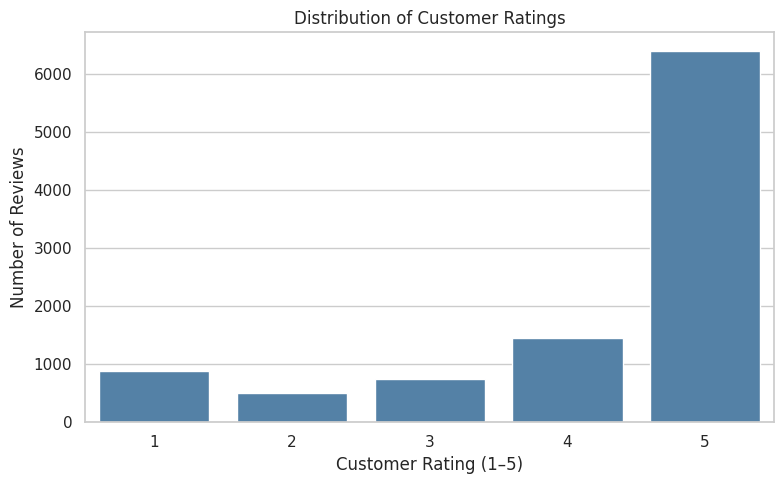

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_sample,
    x="Score",
    order=sorted(df_sample["Score"].dropna().unique()),
    color="steelblue"
)

plt.title("Distribution of Customer Ratings")
plt.xlabel("Customer Rating (1–5)")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

## Text Preprocessing

Text preprocessing prepares customer reviews for sentiment analysis by removing unnecessary formatting and standardising the review text.

The preprocessing process includes:

- Removing HTML tags and URLs.
- Removing unnecessary spaces.
- Converting text to lowercase.
- Preserving punctuation and expressions that may influence sentiment.

The original review text will be preserved for comparison.

The dataset contains one missing review summary but no missing review text. Therefore, sentiment analysis can proceed using the Text column without removing records due to missing summaries.

In [16]:
df_clean = df_sample.copy()

print("Original Sample:", df_sample.shape)
print("Working Dataset:", df_clean.shape)

Original Sample: (10000, 10)
Working Dataset: (10000, 10)


In [17]:
import re
import html

def clean_review(text):
    if pd.isna(text):
        return ""

    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"\s+", " ", text)

    return text.strip()

df_clean["Cleaned_Text"] = (
    df_clean["Text"].apply(clean_review)
)

print("Text preprocessing completed!")

display(
    df_clean[["Text", "Cleaned_Text"]].head()
)

Text preprocessing completed!


,Text,Cleaned_Text
165256,Having tried a couple of other brands of glute...,Having tried a couple of other brands of glute...
231465,My cat loves these treats. If ever I can't fin...,My cat loves these treats. If ever I can't fin...
427827,A little less than I expected. It tends to ha...,A little less than I expected. It tends to hav...
433954,"First there was Frosted Mini-Wheats, in origin...","First there was Frosted Mini-Wheats, in origin..."
70260,and I want to congratulate the graphic artist ...,and I want to congratulate the graphic artist ...


In [18]:
empty_reviews = (
    df_clean["Cleaned_Text"].str.strip() == ""
).sum()

print("Empty Reviews After Cleaning:", empty_reviews)

Empty Reviews After Cleaning: 0


In [19]:
print("Original Review:")
print(df_clean["Text"].iloc[0])

print("\nCleaned Review:")
print(df_clean["Cleaned_Text"].iloc[0])

Original Review:
Having tried a couple of other brands of gluten-free sandwich cookies, these are the best of the bunch.  They're crunchy and true to the texture of the other "real" cookies that aren't gluten-free.  Some might think that the filling makes them a bit too sweet, but for me that just means I've satisfied my sweet tooth sooner!  The chocolate version from Glutino is just as good and has a true "chocolatey" taste - something that isn't there with the other gluten-free brands out there.

Cleaned Review:
Having tried a couple of other brands of gluten-free sandwich cookies, these are the best of the bunch. They're crunchy and true to the texture of the other "real" cookies that aren't gluten-free. Some might think that the filling makes them a bit too sweet, but for me that just means I've satisfied my sweet tooth sooner! The chocolate version from Glutino is just as good and has a true "chocolatey" taste - something that isn't there with the other gluten-free brands out ther

Review Length Statistics:


,Review_Length
count,10000.000000
mean,79.467600
std,76.212874
min,5.000000
25%,34.000000
50%,56.000000
75%,97.000000
max,1288.000000


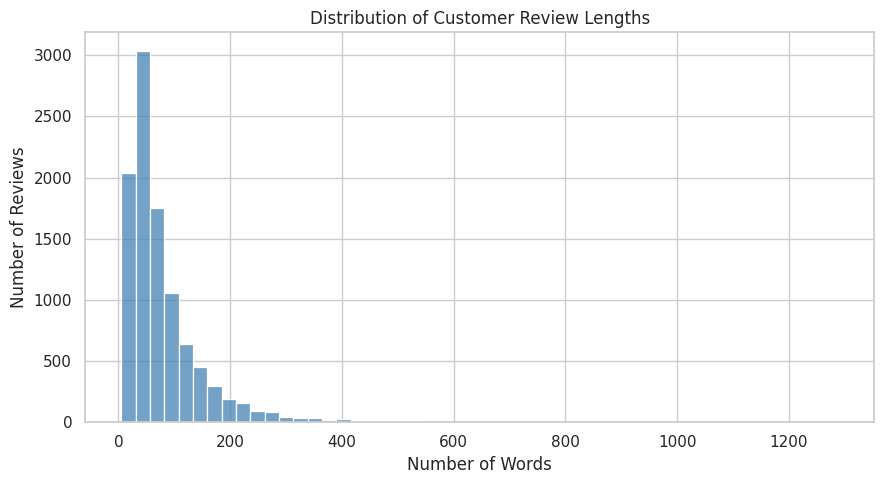

In [20]:
df_clean["Review_Length"] = (
    df_clean["Cleaned_Text"].str.split().str.len()
)

print("Review Length Statistics:")
display(df_clean["Review_Length"].describe())

plt.figure(figsize=(9, 5))

sns.histplot(
    df_clean["Review_Length"],
    bins=50,
    color="steelblue"
)

plt.title("Distribution of Customer Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

### Text Preprocessing Results and Observations

Text preprocessing was performed on 10,000 customer reviews from the Amazon Fine Food Reviews dataset.

After removing HTML formatting, URLs and unnecessary whitespace, no empty reviews were found. All 10,000 records were retained for sentiment analysis.

The average review length was approximately 79.47 words, while the median was 56 words. The shortest review contained 5 words, and the longest contained 1,288 words.

The difference between the mean and median suggests that the review-length distribution is right-skewed, with some relatively long customer reviews.

The cleaned text was stored in a separate column while preserving the original reviews. This prepared the dataset for sentiment classification using VADER.

## Sentiment Classification Using VADER

This stage applies the VADER (Valence Aware Dictionary and sEntiment Reasoner) sentiment analysis model to customer reviews.

VADER is a lexicon-based sentiment analysis tool that assigns sentiment scores based on the words and expressions used in a text.

Each review is classified into one of three categories:

- **Positive:** Compound score ≥ 0.05
- **Negative:** Compound score ≤ -0.05
- **Neutral:** Compound score between -0.05 and 0.05

The results will be used to examine customer sentiment patterns and compare predicted sentiment with customer ratings.

In [21]:
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

nltk.download("vader_lexicon", quiet=True)

sia = SentimentIntensityAnalyzer()

print("VADER sentiment analyser ready!")

VADER sentiment analyser ready!


In [22]:
# Calculate sentiment scores for each review
sentiment_scores = df_clean["Cleaned_Text"].apply(
    sia.polarity_scores
)

# Convert scores into a DataFrame
scores_df = pd.DataFrame(
    sentiment_scores.tolist(),
    index=df_clean.index
)

# Add sentiment scores to the dataset
df_clean["Negative_Score"] = scores_df["neg"]
df_clean["Neutral_Score"] = scores_df["neu"]
df_clean["Positive_Score"] = scores_df["pos"]
df_clean["Compound_Score"] = scores_df["compound"]

print("Sentiment scores calculated successfully!")

display(
    df_clean[
        ["Cleaned_Text", "Compound_Score"]
    ].head()
)

Sentiment scores calculated successfully!


,Cleaned_Text,Compound_Score
165256,Having tried a couple of other brands of glute...,0.9684
231465,My cat loves these treats. If ever I can't fin...,0.7920
427827,A little less than I expected. It tends to hav...,0.4588
433954,"First there was Frosted Mini-Wheats, in origin...",0.9928
70260,and I want to congratulate the graphic artist ...,0.9619


In [23]:
def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df_clean["Sentiment"] = (
    df_clean["Compound_Score"].apply(classify_sentiment)
)

print("Sentiment Classification Completed!")

display(
    df_clean[
        ["Score", "Cleaned_Text",
         "Compound_Score", "Sentiment"]
    ].head(10)
)

Sentiment Classification Completed!


,Score,Cleaned_Text,Compound_Score,Sentiment
165256,5,Having tried a couple of other brands of glute...,0.9684,Positive
231465,5,My cat loves these treats. If ever I can't fin...,0.7920,Positive
427827,3,A little less than I expected. It tends to hav...,0.4588,Positive
433954,2,"First there was Frosted Mini-Wheats, in origin...",0.9928,Positive
70260,5,and I want to congratulate the graphic artist ...,0.9619,Positive
49866,4,Please add more Pineapple flavor to your packa...,0.3182,Positive
551047,5,I absolutely love Yorkshire tea and am so glad...,0.9445,Positive
18983,5,I have such a hard time finding loose tea loca...,0.3595,Positive
138968,4,"Previously, I've attempted a recipe with white...",0.9853,Positive
36352,5,I make pancakes or waffles every Saturday morn...,0.4588,Positive


In [24]:
sentiment_counts = (
    df_clean["Sentiment"]
    .value_counts()
    .reindex(["Positive", "Neutral", "Negative"], fill_value=0)
)

sentiment_percentages = (
    sentiment_counts / len(df_clean) * 100
).round(2)

sentiment_summary = pd.DataFrame({
    "Count": sentiment_counts,
    "Percentage": sentiment_percentages
})

print("Sentiment Distribution:")
display(sentiment_summary)

Sentiment Distribution:


,Count,Percentage
Sentiment,,
Positive,8798,87.98
Neutral,203,2.03
Negative,999,9.99


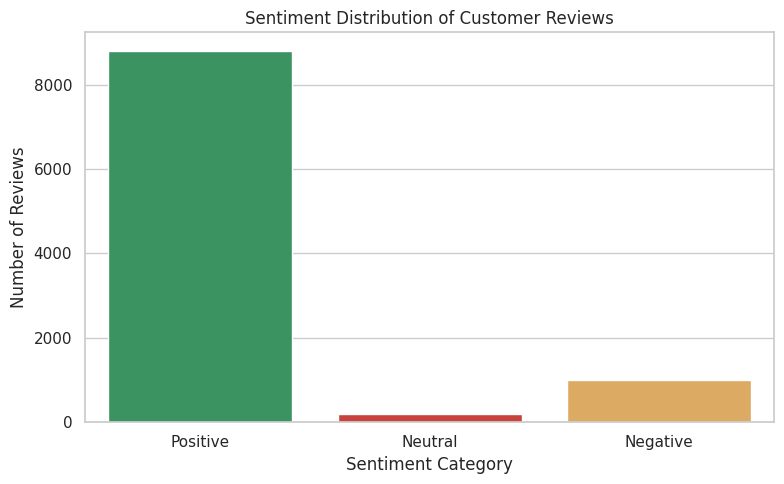

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Sentiment",
    order=["Positive", "Neutral", "Negative"],
    palette=["#2ca25f", "#f0ad4e", "#de2d26"],
    hue="Sentiment",
    legend=False
)

plt.title("Sentiment Distribution of Customer Reviews")
plt.xlabel("Sentiment Category")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

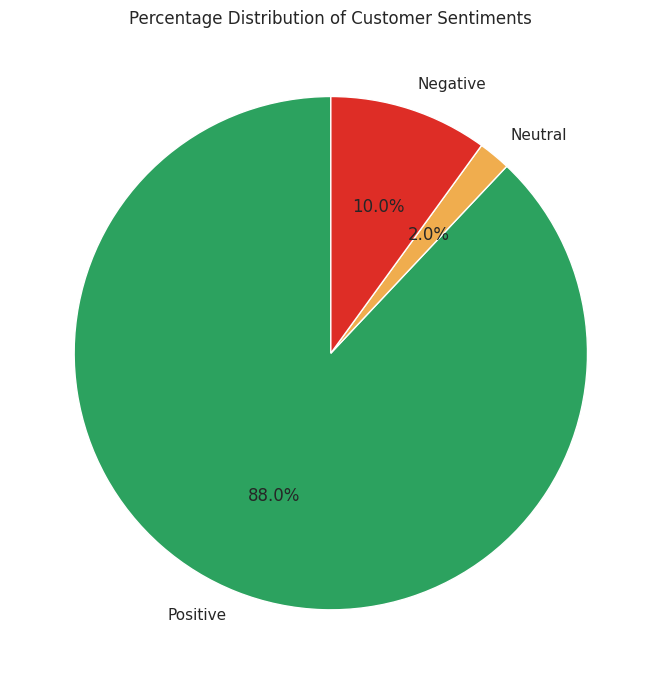

In [26]:
plt.figure(figsize=(7, 7))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#2ca25f", "#f0ad4e", "#de2d26"]
)

plt.title("Percentage Distribution of Customer Sentiments")
plt.tight_layout()
plt.show()

### Sentiment Classification Observations

The VADER sentiment analysis model was applied to the cleaned customer reviews.

Each review received positive, negative, neutral and compound sentiment scores. The compound score was used to classify the review into Positive, Negative or Neutral sentiment.

The sentiment distribution was visualised using a bar chart and a pie chart to examine the relative frequency of each sentiment category.

The results represent automated sentiment estimates based on review text. They may not always match the customer's numerical rating, particularly when reviews contain sarcasm, mixed opinions or context-dependent language.

In [27]:
print(sentiment_summary)

           Count  Percentage
Sentiment                   
Positive    8798       87.98
Neutral      203        2.03
Negative     999        9.99


## Comparison of Predicted Sentiment and Customer Ratings

This analysis compares VADER sentiment classifications with the original customer ratings.

Ratings are grouped into three categories:

- Positive: 4–5 stars
- Neutral: 3 stars
- Negative: 1–2 stars

The comparison helps identify agreement and disagreement between text-based sentiment predictions and customer ratings.

In [28]:
def rating_to_sentiment(rating):
    if rating >= 4:
        return "Positive"
    elif rating == 3:
        return "Neutral"
    else:
        return "Negative"

df_clean["Rating_Sentiment"] = (
    df_clean["Score"].apply(rating_to_sentiment)
)

print("Rating-Based Sentiment Distribution:")
print(df_clean["Rating_Sentiment"].value_counts())

Rating-Based Sentiment Distribution:
Rating_Sentiment
Positive    7852
Negative    1398
Neutral      750
Name: count, dtype: int64


In [29]:
comparison = pd.crosstab(
    df_clean["Rating_Sentiment"],
    df_clean["Sentiment"]
)

comparison = comparison.reindex(
    index=["Positive", "Neutral", "Negative"],
    columns=["Positive", "Neutral", "Negative"],
    fill_value=0
)

print("Sentiment Comparison Table:")
display(comparison)

Sentiment Comparison Table:


Sentiment,Positive,Neutral,Negative
Rating_Sentiment,,,
Positive,7450,107,295
Neutral,596,25,129
Negative,752,71,575


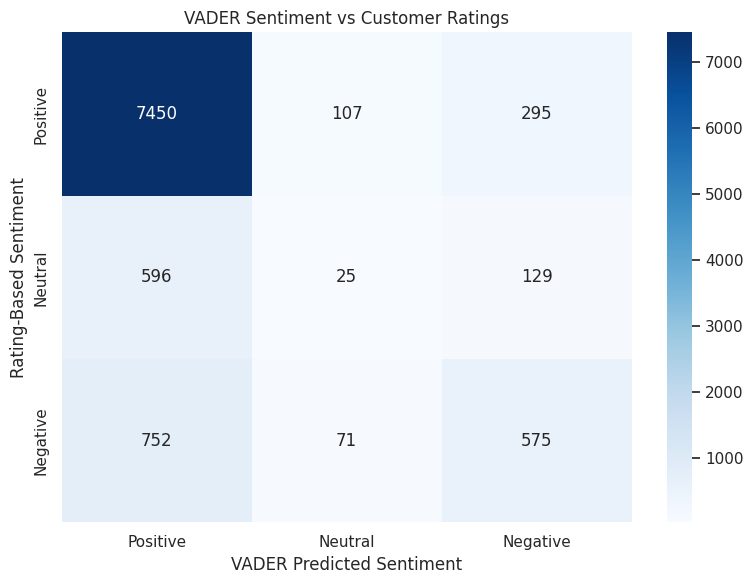

In [30]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    comparison,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("VADER Sentiment vs Customer Ratings")
plt.xlabel("VADER Predicted Sentiment")
plt.ylabel("Rating-Based Sentiment")

plt.tight_layout()
plt.show()

In [31]:
agreement = (
    df_clean["Sentiment"] ==
    df_clean["Rating_Sentiment"]
).mean() * 100

print(f"Agreement Percentage: {agreement:.2f}%")

Agreement Percentage: 80.50%


In [32]:
mismatched = df_clean[
    df_clean["Sentiment"] != df_clean["Rating_Sentiment"]
]

print("Number of Mismatched Reviews:", len(mismatched))

display(
    mismatched[
        ["Score", "Rating_Sentiment",
         "Sentiment", "Cleaned_Text"]
    ].head(10)
)

Number of Mismatched Reviews: 1950


,Score,Rating_Sentiment,Sentiment,Cleaned_Text
427827,3,Neutral,Positive,A little less than I expected. It tends to hav...
433954,2,Negative,Positive,"First there was Frosted Mini-Wheats, in origin..."
446394,5,Positive,Negative,Luckily this is available locally so I got to ...
492897,1,Negative,Positive,It sure would be nice if they stated ANYWHERE ...
234760,1,Negative,Positive,I bought this item for my dog to play with. Sh...
158426,3,Neutral,Positive,I ordered these when I found out the Morningst...
363913,3,Neutral,Positive,Edit: I've given this three stars vs my previo...
286013,3,Neutral,Negative,I've noticed that with a lot of products on th...
38015,1,Negative,Neutral,I planted mine in a separate area next to my y...
547722,3,Neutral,Positive,I am totally addicted to POPCHIPS! This is a v...


### Sentiment Comparison Results and Observations

The VADER sentiment predictions were compared with sentiment categories derived from customer ratings.

Out of 10,000 reviews, 8,050 received matching sentiment classifications, resulting in an overall agreement of 80.50%. The remaining 1,950 reviews (19.50%) showed differences between the two classification methods.

Among reviews with positive ratings, 7,450 were classified as positive by VADER. However, 752 reviews with negative ratings were classified as positive, while 596 reviews with neutral ratings were also classified as positive.

These findings indicate that VADER generally aligns with customer ratings but does not always interpret customer opinions in the same way. Differences may arise from mixed sentiments, contextual language, sarcasm or limitations of lexicon-based analysis.

The agreement percentage measures consistency with rating-derived labels rather than definitive model accuracy.

## Word Cloud Visualisation

Word clouds are used to visualise frequently occurring words in customer reviews.

Separate word clouds are generated for positive and negative reviews to identify common terms associated with each sentiment category.

These visualisations provide an overview of word frequency but do not independently establish whether individual words express positive or negative opinions.

In [33]:
from wordcloud import WordCloud, STOPWORDS

print("WordCloud library imported successfully!")

WordCloud library imported successfully!


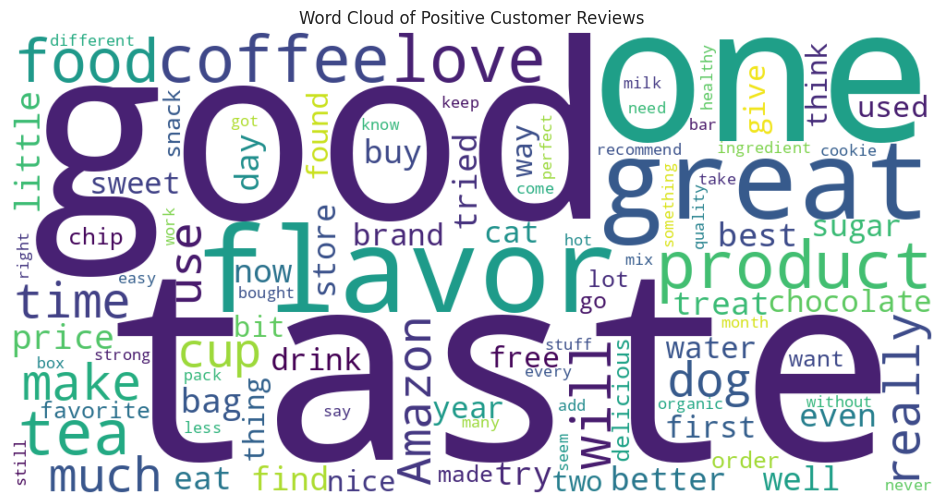

In [34]:
positive_text = " ".join(
    df_clean.loc[
        df_clean["Sentiment"] == "Positive",
        "Cleaned_Text"
    ]
)

positive_cloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    stopwords=STOPWORDS,
    max_words=100,
    collocations=False,
    random_state=42
).generate(positive_text)

plt.figure(figsize=(12, 6))
plt.imshow(positive_cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Positive Customer Reviews")
plt.show()

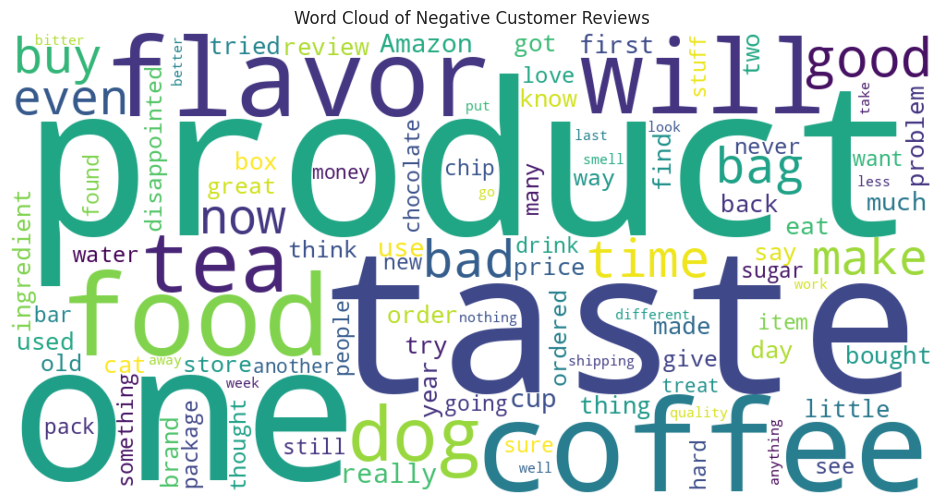

In [35]:
negative_text = " ".join(
    df_clean.loc[
        df_clean["Sentiment"] == "Negative",
        "Cleaned_Text"
    ]
)

negative_cloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    stopwords=STOPWORDS,
    max_words=100,
    collocations=False,
    random_state=42
).generate(negative_text)

plt.figure(figsize=(12, 6))
plt.imshow(negative_cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Negative Customer Reviews")
plt.show()

In [36]:
from collections import Counter
import re

def top_words(text, n=15):
    words = re.findall(r"\b[a-z]+\b", text.lower())
    words = [
        word for word in words
        if word not in STOPWORDS and len(word) > 2
    ]
    return Counter(words).most_common(n)

print("Top 15 Words in Positive Reviews:")
print(top_words(positive_text))

print("\nTop 15 Words in Negative Reviews:")
print(top_words(negative_text))

Top 15 Words in Positive Reviews:
[('good', 3330), ('great', 2857), ('one', 2750), ('taste', 2705), ('coffee', 2602), ('product', 2347), ('tea', 2345), ('flavor', 2308), ('love', 2144), ('food', 1963), ('will', 1951), ('really', 1558), ('much', 1479), ('amazon', 1478), ('little', 1363)]

Top 15 Words in Negative Reviews:
[('product', 358), ('taste', 340), ('one', 331), ('coffee', 275), ('food', 242), ('will', 228), ('tea', 211), ('flavor', 198), ('good', 196), ('don', 194), ('bad', 175), ('buy', 159), ('even', 152), ('now', 150), ('dog', 148)]


### Word Cloud Analysis and Observations

The word clouds highlight frequently occurring terms in positive and negative customer reviews.

The positive review word cloud prominently displays words such as "good", "taste", "love", "coffee", and "product". These terms suggest that product quality, taste and overall customer experience are common discussion topics.

The negative review word cloud includes words such as "taste", "flavor", "product", "coffee", "bad", and "disappointed". These reviews frequently discuss product experiences, although word frequency alone cannot establish the reasons for dissatisfaction.

Several words appear in both word clouds, indicating that the same product attributes are discussed across different sentiment categories.

Word clouds provide a useful overview of common vocabulary but should be interpreted alongside the sentiment classification results.

In [37]:
total_reviews = len(df_clean)

positive = (df_clean["Sentiment"] == "Positive").sum()
neutral = (df_clean["Sentiment"] == "Neutral").sum()
negative = (df_clean["Sentiment"] == "Negative").sum()

agreement = (
    df_clean["Sentiment"] ==
    df_clean["Rating_Sentiment"]
).mean() * 100

print("===== SENTIMENT ANALYSIS PROJECT SUMMARY =====")
print("Total Reviews:", total_reviews)
print(f"Positive Reviews: {positive} ({positive/total_reviews*100:.2f}%)")
print(f"Neutral Reviews: {neutral} ({neutral/total_reviews*100:.2f}%)")
print(f"Negative Reviews: {negative} ({negative/total_reviews*100:.2f}%)")
print(f"Rating Agreement: {agreement:.2f}%")
print(f"Average Rating: {df_clean['Score'].mean():.2f}")
print(f"Average Review Length: {df_clean['Review_Length'].mean():.2f} words")

===== SENTIMENT ANALYSIS PROJECT SUMMARY =====
Total Reviews: 10000
Positive Reviews: 8798 (87.98%)
Neutral Reviews: 203 (2.03%)
Negative Reviews: 999 (9.99%)
Rating Agreement: 80.50%
Average Rating: 4.20
Average Review Length: 79.47 words


## Conclusion

This project analysed 10,000 customer reviews from the Amazon Fine Food Reviews dataset using Python and Natural Language Processing techniques.

The review text was cleaned by removing HTML formatting, URLs and unnecessary whitespace. VADER sentiment analysis was then used to classify customer opinions into positive, negative and neutral categories.

The results showed that 87.98% of reviews were classified as positive, 9.99% as negative and 2.03% as neutral. These findings suggest that positive sentiment was dominant in the selected sample.

A comparison between VADER predictions and customer rating categories produced an agreement of 80.50%. The remaining 19.50% of reviews showed differences between text-based sentiment predictions and rating-derived sentiment labels.

Word cloud visualisations highlighted frequently discussed terms, including product, taste, flavor and coffee. These terms appeared across different sentiment categories, demonstrating that word frequency alone does not determine sentiment.

Overall, the project demonstrates how lexicon-based sentiment analysis can be used to examine customer opinions and identify broad sentiment patterns in review data.

## Limitations

- VADER may struggle with sarcasm, mixed opinions and context-dependent expressions.
- Customer ratings do not always represent the sentiment expressed in review text.
- The dataset contains a higher proportion of positive reviews, which affects the distribution of results.
- The analysis was performed on a random sample of 10,000 reviews rather than the complete dataset.
- Word clouds show frequent terms but do not explain the context or causes of customer satisfaction and dissatisfaction.

## Future Scope

Future improvements could include comparing VADER with machine learning models such as Logistic Regression or Linear SVM, evaluating predictions against manually labelled reviews, and performing aspect-based sentiment analysis to identify specific product features associated with customer opinions.

In [38]:
output_file = "Amazon_Reviews_Sentiment_Analysis.csv"

df_clean.to_csv(output_file, index=False)

print("Dataset saved successfully!")
print("File:", output_file)
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))

Dataset saved successfully!
File: Amazon_Reviews_Sentiment_Analysis.csv
Rows: 10000
Columns: 18


In [39]:
from google.colab import files

files.download("Amazon_Reviews_Sentiment_Analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>